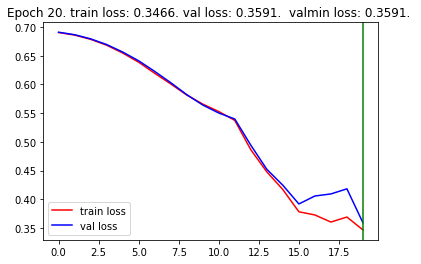

Epoch Duration: 11.32741403579712's
Total duration is: 236.88264298439026's
The best epoch is at: 20 th epoch
Train loss list is: [0.690493086973826, 0.6860469778378805, 0.6786441008249918, 0.668425460656484, 0.6547721028327942, 0.6387630899747213, 0.6195007562637329, 0.6009681224822998, 0.5815859039624532, 0.5658296545346578, 0.5528653661410013, 0.5373962124188741, 0.48629533251126605, 0.44778120517730713, 0.4169413348038991, 0.37821723024050397, 0.37269944945971173, 0.3603411714235942, 0.3690768877665202, 0.34663793444633484]
Val   loss list is: [0.6909831166267395, 0.6867281794548035, 0.6794835329055786, 0.6695485711097717, 0.6565511226654053, 0.6411969065666199, 0.6227737069129944, 0.6031494140625, 0.5823215246200562, 0.5642010569572449, 0.5502660274505615, 0.5398562550544739, 0.4942120909690857, 0.4521873891353607, 0.4244457185268402, 0.3918776214122772, 0.40570536255836487, 0.4093201160430908, 0.418204128742218, 0.3590652346611023]
Analyzing 019.png
The vi of 019.png is 0.1845132

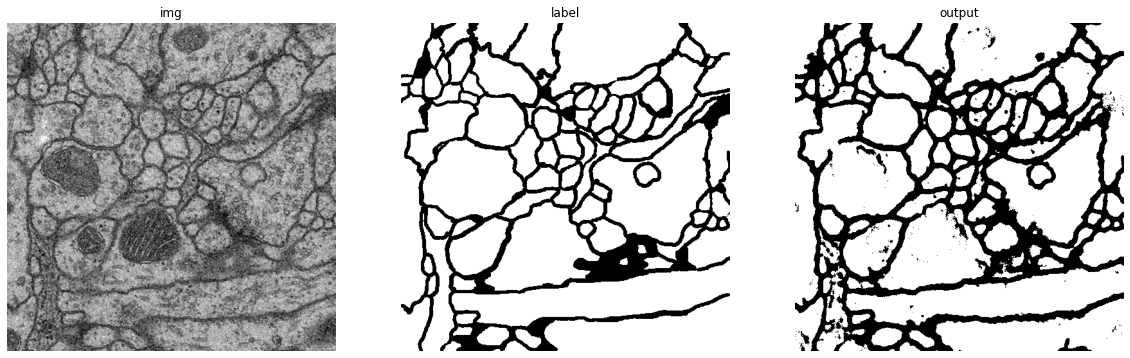

Analyzing 005.png
The vi of 005.png is 0.21508418046039418
Image size is (512, 512),    min is 1, max is 253
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


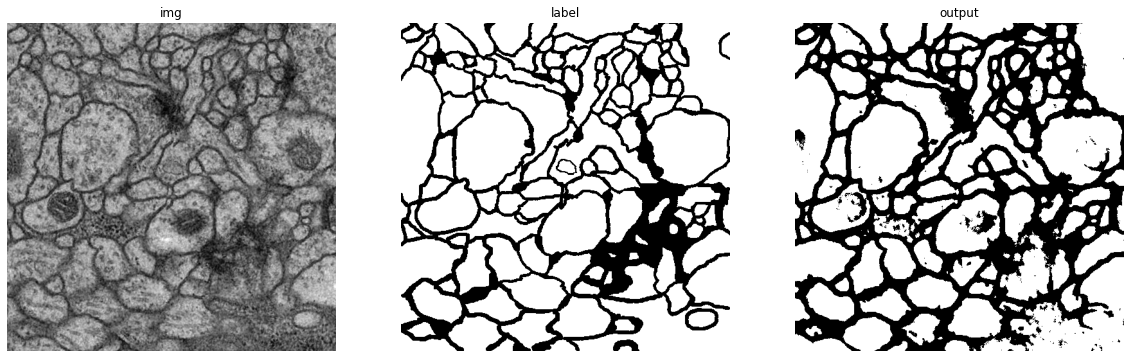

Analyzing 028.png
The vi of 028.png is 0.08353735515712216
Image size is (512, 512),    min is 0, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


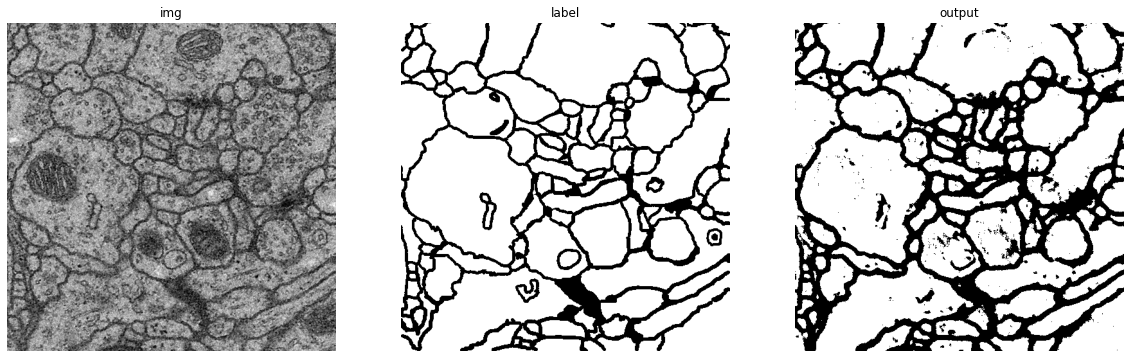

Analyzing 009.png
The vi of 009.png is 0.3361667122485254
Image size is (512, 512),    min is 4, max is 251
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


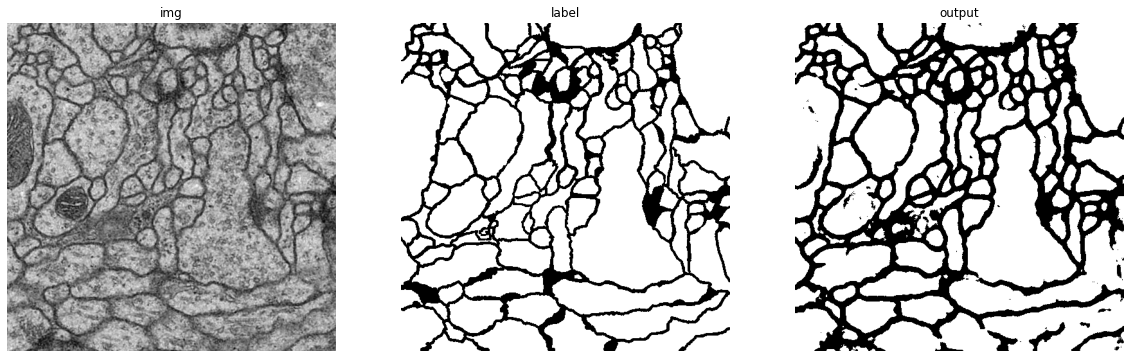

Analyzing 003.png
The vi of 003.png is 0.2084666034574726
Image size is (512, 512),    min is 3, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


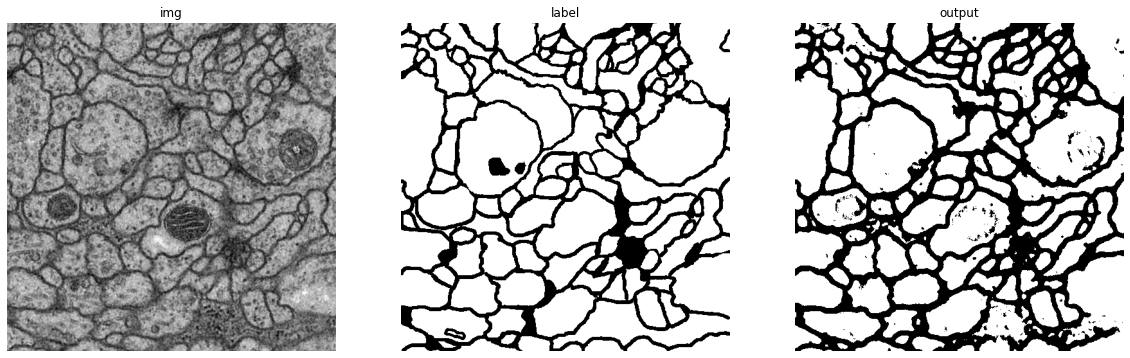

Analyzing 024.png
The vi of 024.png is 0.277925914235684
Image size is (512, 512),    min is 0, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


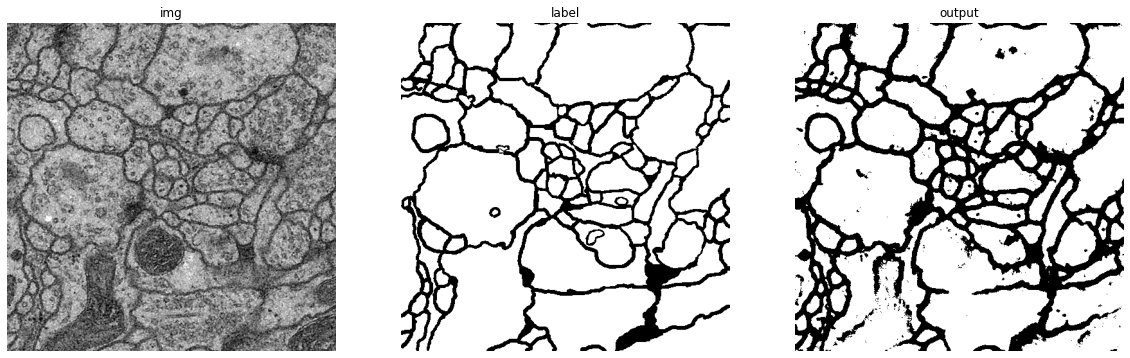

test_metrics is [0.2176156672635784]
Experiment is /maboyuan/ImageSegmentation/experiment/seg_isbi2012_unet_loss_bcw_XXXXXXX
Metric is vi in test time
The test value is: 0.2176156672635784
Starting inference: seg_isbi2012_unet_loss_bcw_XXXXXXX
Analyzing all the images
Analyzing 006.png
The vi of 006.png is 0.13586659984488797
Image size is (512, 512),    min is 2, max is 250
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


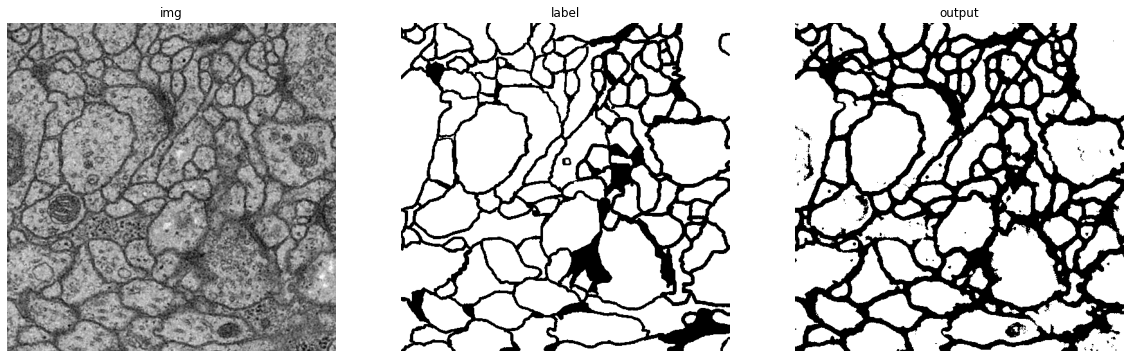

Analyzing 026.png
The vi of 026.png is 0.20002082494144363
Image size is (512, 512),    min is 0, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


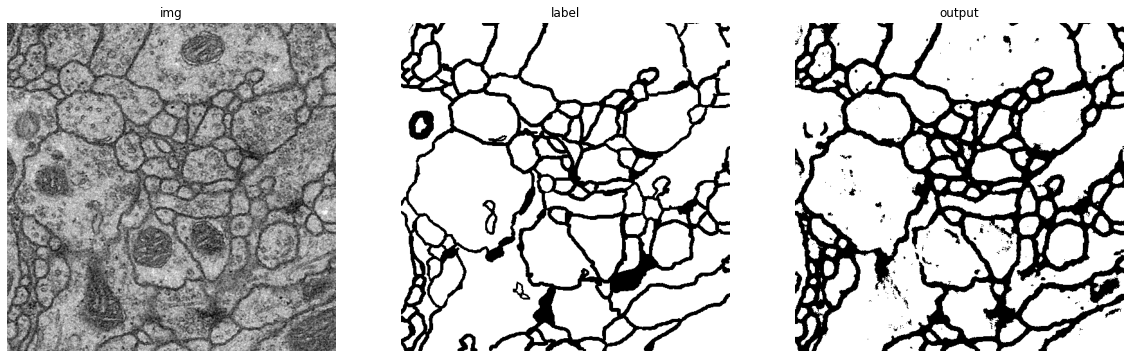

Analyzing 019.png
The vi of 019.png is 0.18451323802227204
Image size is (512, 512),    min is 0, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


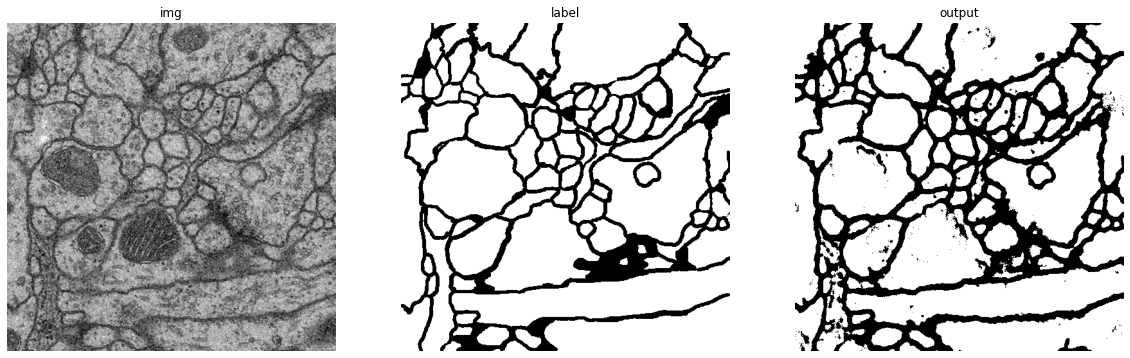

Analyzing 002.png
The vi of 002.png is 0.09770502267522094
Image size is (512, 512),    min is 2, max is 255
Label size is (512, 512),    min is 0.0, max is 1.0
Output size is (512, 512),   min is 0.0, max is 1.0


KeyboardInterrupt: 

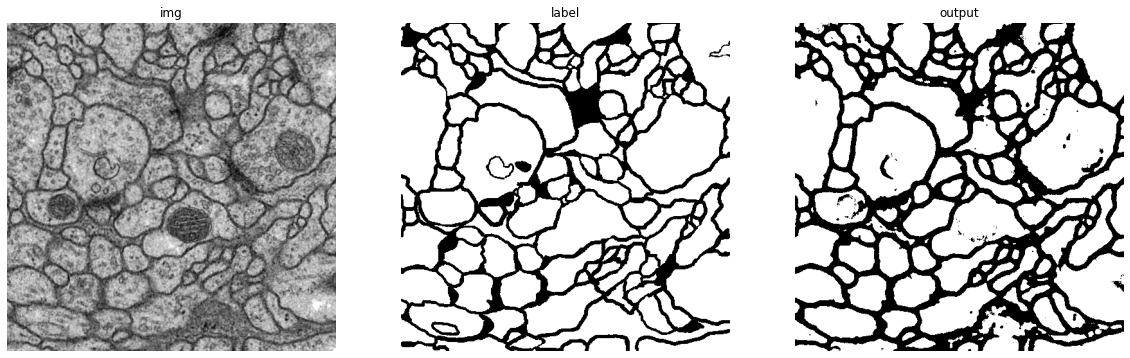

In [1]:
import os
from pathlib import Path
import h5py
from IPython.display import clear_output
import matplotlib.pyplot as plt
%matplotlib inline

import cv2, time
import random
import skimage
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as tr
from sklearn.model_selection import KFold
from skimage import morphology
# import pandas as pd

from utils import *

from model.segtrainer import SegTrainer
from model.seginferencer import SegInferencer
from model.losses import losser

# you can write your own func of data_preprocess begin at training
def data_preprocess(in_dir: Path, out_dir: Path, suffix: str = "png", labels_class_num: int = 2) -> Tuple:
    """
        Prepare the data for training
        The data can be download from ISBI2012 challange (website: 'http://brainiac2.mit.edu/isbi_challenge/')
        :param in_dir:  the input directory of origin data 
        :param out_dir: the output directory of processed data
        :param suffix:  the suffix of raw image file
        :param labels_class_num: the number of class in label
        :return: (mean, std, num) of raw image, which is used for normalization
    """
    
    # can not read libtif in numpy 0.19 and libtiff 0.4
    # imgs_inpath = Path(in_dir, "train-volume.tif")
    # labels_inpath = Path(in_dir, "train-labels.tif")
    # imgs_tif = TIFF.open(imgs_inpath, mode='r')
    # labels_tif = TIFF.open(labels_inpath, mode='r')

    imgs_outpath = Path(out_dir, "images")
    labels_outpath = Path(out_dir, "labels")
    imgs_outpath.mkdir(parents=True, exist_ok=True) 
    labels_outpath.mkdir(parents=True, exist_ok=True)
    
    print("File Converting...")
    print("The image's path is {}".format(str(imgs_outpath  )))
    print("The label's path is {}".format(str(labels_outpath)))
    
    # can not read libtif in numpy 0.19 and libtiff 0.4
    # idx = -1
    # zfill_num = len(str(len(list(imgs_tif.iter_images())))) + 1 # pad 0 before file name
    # for img, label in zip( list(imgs_tif.iter_images()),  list(labels_tif.iter_images()) ):
    #     idx += 1
    #     io.imsave(str(Path(imgs_outpath, str(idx).zfill(zfill_num) + '.' + imgs_suffix)), img)
    #     np.save(str(Path(labels_outpath, str(idx).zfill(zfill_num) + ".npy")), (label/255))  # cell is 1 and border is 0
    #     if idx == 0:
    #         plt.figure(figsize=(10, 10))
    #         plt.subplot(1, 2, 1), plt.imshow(img,   cmap="gray"), plt.title("image"), plt.axis("off")
    #         plt.subplot(1, 2, 2), plt.imshow(label, cmap="gray"), plt.title("label"), plt.axis("off")
    #         plt.show()
    
    # unzip the data_experiment.zip file
    zip_pth = Path(out_dir.parent, "data_experiment.zip")
    unzip_file(zip_pth, out_dir.parent)
    
    # it is useful for your data preprocessing function
    print("Generating weight map...")
    weights_func = ["bcw", "uw"]
    losser.prepare_weight_map(labels_outpath, out_dir, weights_func, labels_class_num)  
    print("Generated weight map in {}".format(str(out_dir)))
    
    mean, std, num = count_mean_and_std(imgs_outpath, suffix)
    print("mean = {}, std ={} and image num = {}".format(mean, std, num))
    print("Data Preprocess has done")
    
    return mean, std, num


# you can define your own data_postprocess in the step of inference
def data_postprocess(in_img: np.ndarray) -> np.ndarray:
    """
        post processing data after inference before evaluation
        :param in_img:
        :return out_img:
    """
    # skeletonization of result
    # out_img = morphology.skeletonize(1 - in_img, method="lee") /255 # Lee Skeleton method
    # dialiation with 3 pixels
    # out_img = 1 - morphology.dilation(out_img, morphology.square(3))
    return in_img


def train(data_name: str, data_bk_dir: Path, data_dir: Path, params_path: Path, custom_desc: str) -> str:
    """
        Train netowrk
        :param data_name:
        :param data_bk_dir:  the input directory of origin data 
        :param data_dir:     the output directory of processed data
        :param params_path:  the path of certain experimental parameters
        :param custom_desc:  the custom description which add last in the experiment_name, you can define it
        :return: experiment_name, which is used to record all the parameter in training
    """
    
    # load params of experiment
    params = ParamsYml().load_params(params_path)
    
    # data preprocess
    mean, std, num = data_preprocess(data_bk_dir, data_dir, suffix = params["data"]["imgs_suffix"], 
                                     labels_class_num = params["data"]["labels_class_num"])
    
    
    # you can direct assign values in here in order to avoid repeat execution of data_preprocess
    # for isibi2012, mean = 0.49475772084753505, std = 0.1678160259016179 and image num = 30
    params["data"]["name"]      = data_name
    params["data"]["dir"]       = str(data_dir)
    params["data"]["imgs_mean"] = 0.49475772084753505
    params["data"]["imgs_std"]  = 0.1678160259016179
    params["data"]["imgs_num"]  = 30
    
    
    experiment_name = set_experiment_name(params, custom_desc)
    
    experiment_dir  = Path(Path.cwd(), "experiment", experiment_name)
    experiment_dir.mkdir(parents=True, exist_ok=True)
    print("Parameters will be saved in {}".format(str(experiment_dir)))
    
    seg_trainer = SegTrainer(params, experiment_dir, data_postprocess)
    
    # Training
    seg_trainer.start_training()
    
    return experiment_name


def inference(experiment_name: str) -> None:
    """
        inference data according to previous training record
        :param experiment_name: which is used to record all the parameter in training
    """
    # Wether to analyse all data or only test dataset 
    is_test_all = True
    seg_trainer = SegInferencer(experiment_name, is_test_all, data_postprocess)
    seg_trainer.start_inference()


if __name__ == '__main__':
    
    data_name   = "isbi2012"
    data_bk_dir = Path(Path.cwd(), "data", data_name, "data_backup")
    data_dir    = Path(Path.cwd(), "data", data_name, "data_experiment")
    params_path = Path(Path.cwd(), "isbi2012_bcw.yml")
    custom_desc = "XXXXXXX"          # you can add your description in here
    
    # Tranining
    experiment_name = train(data_name, data_bk_dir, data_dir, params_path, custom_desc)
    
    
    # Inference
    experiment_name = "seg_isbi2012_unet_loss_bcw_XXXXXXX"
    inference(experiment_name)